# 16 — Calibração, segmentos e robustez no corte de decisão

**Perguntas.** O score do modelo ponderado se comporta como probabilidade de inadimplência? Onde os erros se concentram? Como erros graduais de medição da utilização rotativa, de −50% a +50% em passos de 5%, afetam as quatro métricas centrais e as decisões perto do corte fixo de **0,50**? Executamos a grade completa sem critério de parada.

O modelo é o retreino com `scale_pos_weight=13.882494684620836`. Usamos somente o *holdout* rotulado reconstruído com o mesmo `train_test_split` do notebook 00. `cs-test.csv` não tem rótulos e não participa destas métricas. A seleção das bandas usa apenas o **score original**, sem olhar o desfecho. Em seguida, perturbamos **somente a entrada entregue ao modelo**; o valor real do cliente e seu desfecho histórico não são alterados. Isso representa um erro de medição, para o qual manter o rótulo é defensável. Não representa uma mudança real da utilização do cliente.

`scale_pos_weight` aumenta o peso dos casos positivos na função de perda do treinamento. Com isso, o score produzido por `binary:logistic` **não deve ser presumido uma probabilidade de inadimplência calibrada**. Não calibramos nem mudamos o limiar neste exercício; apenas medimos suas consequências.

## Dicionário rápido e siglas

| Termo | Definição e sentido |
|---|---|
| PD | Probabilidade de inadimplência. Exige validação de calibração; um score de classificação não a garante. |
| Score | Saída de `Booster.predict` para a classe positiva. |
| Brier (BS) | Média de `(y-score)²`; menor é melhor. |
| Brier skill (BSS) | `1 − BS_modelo/BS_referência`; positivo indica ganho frente ao preditor constante escolhido. |
| ROC AUC | Probabilidade de um positivo receber score maior que um negativo, com correção para empates; avalia ordenação. |
| PR-AUC trapezoidal | Área `auc(recall_curve, precision_curve)`; resume a curva precisão–recall por trapézios e depende da prevalência. |
| KS do modelo | Maior diferença entre TPR e FPR ao longo dos limiares de score; usa rótulos e scores. Não é KS de drift entre entradas. |
| AP | *Average precision*, resumo adicional da curva precisão–recall; é diferente da PR-AUC trapezoidal. |
| Recall | `TP/(TP+FN)`: fração dos positivos identificados no corte. |
| Precisão | `TP/(TP+FP)`: fração dos sinalizados que realmente são positivos no corte; pode ser indefinida. |
| FPR | `FP/(FP+TN)`: fração dos negativos sinalizados no corte. |
| PSI | Índice de estabilidade populacional calculado em faixas fixas; mede mudança de distribuição, não perda de desempenho. |
| Flip | Cliente cuja decisão `score ≥ 0,50` muda após o erro de medição. |
| Banda de fronteira | Subgrupo com `abs(score original − 0,50) ≤ largura`; as bandas são aninhadas. |

**Legenda das matrizes:** TP = positivo real previsto positivo; FN = positivo real previsto negativo; FP = negativo real previsto positivo; TN = negativo real previsto negativo. TPR = TP/(TP+FN) e FPR = FP/(FP+TN) no limiar analisado. Neste notebook todas as métricas supervisionadas usam o rótulo verdadeiro do *holdout*. Recall e precisão em 0,50 são referenciais descritivos, sem critério de parada. [Fontes oficiais: PR curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html), [área trapezoidal](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html), [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [ROC curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html) e [Brier](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html).

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, auc)

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / 'cs-training.csv').is_file()), None)
assert DATA_DIR is not None, 'Abra o notebook a partir da raiz do projeto ou notebooks/.'
OUT = TABLES_DIR
MANIFESTO = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding='utf-8'))
ARQUIVO_MODELO = MODEL_DIR / 'model_class_retreinado.json'
assert np.isclose(MANIFESTO['params_fornecidos']['scale_pos_weight'],
                  13.882494684620836, rtol=0, atol=1e-12)
assert MANIFESTO['cutoff'] == 0.50
assert hashlib.sha256(ARQUIVO_MODELO.read_bytes()).hexdigest() == MANIFESTO['model_sha256']
FEATURES = MANIFESTO['features']
ALVO = MANIFESTO['target']
CORTE = float(MANIFESTO['cutoff'])
SEED = int(MANIFESTO['seed_split'])
assert hashlib.sha256((DATA_DIR / 'cs-training.csv').read_bytes()).hexdigest() == MANIFESTO['fonte_training_sha256']

bruto = pd.read_csv(DATA_DIR / 'cs-training.csv').drop(columns='Unnamed: 0')
assert list(bruto.drop(columns=ALVO).columns) == FEATURES
assert bruto[ALVO].notna().all()
X_total, y_total = bruto[FEATURES], bruto[ALVO].astype(int)
X_tv, X_hold, y_tv, y_hold = train_test_split(
    X_total, y_total, test_size=.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=.1765, random_state=SEED)
assert (len(X_train), len(X_val), len(X_hold)) == (104996, 22504, 22500)
X_hold = X_hold.reset_index(drop=True)
y_hold = y_hold.reset_index(drop=True)
y = y_hold.to_numpy(dtype=int)

modelo = xgb.Booster(model_file=str(ARQUIVO_MODELO))
modelo.set_param({'device': 'cpu'})
assert modelo.feature_names == FEATURES
assert modelo.num_boosted_rounds() == MANIFESTO['num_boosted_rounds']

def prever(X):
    d = xgb.DMatrix(X[FEATURES], feature_names=FEATURES, enable_categorical=True)
    p = np.asarray(modelo.predict(d), dtype=float)
    assert len(p) == len(X) and np.isfinite(p).all()
    return p

p0 = prever(X_hold)
assert np.isclose(roc_auc_score(y, p0), MANIFESTO['baseline_holdout']['auc_roc'], atol=1e-6, rtol=0)
print(f'Holdout: {len(y):,} casos, {y.sum():,} positivos; treino: {len(y_train):,}; corte: {CORTE:.2f}')
print('Peso de classe:', MANIFESTO['params_fornecidos']['scale_pos_weight'],
      '| árvores:', modelo.num_boosted_rounds(), '| versão:', MANIFESTO['variant'])

Holdout: 22,500 casos, 1,500 positivos; treino: 104,996; corte: 0.50
Peso de classe: 13.882494684620836 | árvores: 103 | versão: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Linha de base e Brier skill

Para cada cliente $i$, $y_i\in\{0,1\}$ é o desfecho e $s_i\in[0,1]$ é o score. O **Brier** é

\[BS = \frac{1}{n}\sum_{i=1}^{n}(y_i-s_i)^2.\]

O preditor constante usa a **prevalência do treino** $\pi_{tr}=\sum_{i\in tr} y_i/n_{tr}$, estimada sem consultar os rótulos do *holdout*. Seu Brier no *holdout* é $BS_{const}=n^{-1}\sum_i(y_i-\pi_{tr})^2$. Definimos

\[BSS=1-\frac{BS_{modelo}}{BS_{const}}.\]

**Legenda:** $n$ é o número de linhas do *holdout*; $BS_{modelo}$ usa os scores do modelo; $BS_{const}$ usa o mesmo valor $\pi_{tr}$ para todos; $BSS<0$ indica Brier pior que essa referência. A referência constante não é uma solução de crédito, apenas um teste de qualidade probabilística. ROC AUC, PR-AUC e KS avaliam separação e ordenação, mas não substituem calibração.

In [3]:
def metricas(yy, pp):
    yy = np.asarray(yy, dtype=int)
    pp = np.asarray(pp, dtype=float)
    pred = pp >= CORTE
    tp = int(np.count_nonzero((yy == 1) & pred))
    fn = int(np.count_nonzero((yy == 1) & ~pred))
    fp = int(np.count_nonzero((yy == 0) & pred))
    tn = int(np.count_nonzero((yy == 0) & ~pred))
    tem_duas_classes = np.unique(yy).size == 2
    if tem_duas_classes:
        precisao_curva, recall_curva, _ = precision_recall_curve(yy, pp)
        fpr_curva, tpr_curva, _ = roc_curve(yy, pp, drop_intermediate=False)
    return {
        'n': len(yy), 'positivos': int(yy.sum()), 'prevalencia': float(yy.mean()),
        'auc_roc': float(roc_auc_score(yy, pp)) if tem_duas_classes else np.nan,
        'pr_auc_trap': float(auc(recall_curva, precisao_curva)) if tem_duas_classes else np.nan,
        'ks_modelo': float(np.max(tpr_curva-fpr_curva)) if tem_duas_classes else np.nan,
        'ap': float(average_precision_score(yy, pp)) if tem_duas_classes else np.nan,
        'brier': float(brier_score_loss(yy, pp)),
        'recall_050': tp/(tp+fn) if tp+fn else np.nan,
        'fpr_050': fp/(fp+tn) if fp+tn else np.nan,
        'precision_050': tp/(tp+fp) if tp+fp else np.nan,
        'taxa_acima_050': float(pred.mean()), 'score_medio': float(pp.mean()),
    }

base = metricas(y, p0)
prevalencia_treino = float(y_train.mean())
brier_constante = float(brier_score_loss(y, np.full(len(y), prevalencia_treino)))
brier_skill = 1 - base['brier']/brier_constante
quadro_base = pd.DataFrame([{
    'prevalencia_treino_constante': prevalencia_treino,
    'brier_predit_constante': brier_constante,
    'brier_skill': brier_skill,
    **base,
}])
display(quadro_base.T.rename(columns={0:'valor'}).round(6))
quadro_base.to_csv(OUT / '16_baseline_calibracao.csv', index=False, encoding='utf-8-sig')
assert np.isclose(base['brier'], MANIFESTO['baseline_holdout']['brier'], atol=1e-6, rtol=0)
for chave in ['auc_roc', 'pr_auc_trap', 'ks_modelo', 'ap']:
    assert np.isclose(base[chave], MANIFESTO['baseline_holdout'][chave], atol=1e-6, rtol=0), chave

,valor
prevalencia_treino_constante,0.067193
brier_predit_constante,0.062222
brier_skill,-1.314892
n,22500.000000
positivos,1500.000000
prevalencia,0.066667
auc_roc,0.866840
pr_auc_trap,0.395991
ks_modelo,0.587714
ap,0.396385


## 2. Curva de calibração por décimos de frequência

Dividimos os **scores** do *holdout* em até dez faixas com números semelhantes de clientes, sem olhar $Y$ para definir cortes. Em cada faixa $b$, $\bar s_b$ é o score médio e $\bar y_b$ a frequência observada de inadimplência. Se o score fosse uma PD bem calibrada, os pontos ficariam próximos de $\bar y_b=\bar s_b$. Reportamos `n` e positivos em cada ponto; faixas pequenas ou com poucos eventos são mais incertas.

Também calculamos o erro médio de calibração por faixas: $ECE=\sum_b(n_b/n)|\bar y_b-\bar s_b|$. **Legenda:** $n_b$ é o tamanho da faixa; $n$ é o total; $ECE$ é um resumo dependente dos cortes escolhidos e pode esconder erros que se compensam dentro da faixa. A curva e o Brier dão visões complementares.

,bin,n,positivos,score_min,score_max,score_medio,taxa_observada,erro_abs
0,0,2250,6,0.03601,0.07354,0.05995,0.00267,0.05728
1,1,2250,18,0.07354,0.09851,0.08588,0.00800,0.07788
2,2,2250,22,0.09853,0.12936,0.11322,0.00978,0.10345
3,3,2250,22,0.12936,0.16849,0.14742,0.00978,0.13764
4,4,2250,36,0.16850,0.22542,0.19528,0.01600,0.17928
5,5,2250,58,0.22544,0.31217,0.26693,0.02578,0.24115
6,6,2250,84,0.31223,0.42536,0.36741,0.03733,0.33008
7,7,2250,163,0.42537,0.56423,0.49429,0.07244,0.42184
8,8,2250,269,0.56424,0.74564,0.64360,0.11956,0.52405
9,9,2250,822,0.74573,0.97662,0.86599,0.36533,0.50065


ECE por décimos: 0.25733 | Brier skill: -1.31489


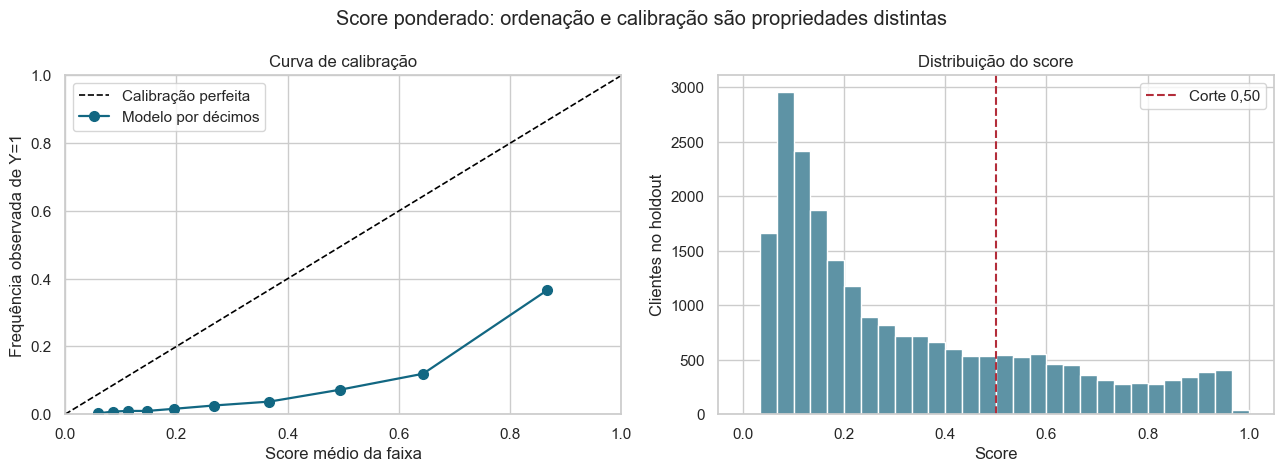

In [4]:
cal = pd.DataFrame({'score': p0, 'y': y})
cal['bin'] = pd.qcut(cal['score'], q=10, labels=False, duplicates='drop')
bins = cal.groupby('bin', observed=True).agg(
    n=('y', 'size'), positivos=('y', 'sum'), score_min=('score', 'min'),
    score_max=('score', 'max'), score_medio=('score', 'mean'),
    taxa_observada=('y', 'mean')).reset_index()
bins['erro_abs'] = (bins['taxa_observada']-bins['score_medio']).abs()
ece = float(np.average(bins['erro_abs'], weights=bins['n']))
bins.to_csv(OUT / '16_calibracao_bins.csv', index=False, encoding='utf-8-sig')
quadro_base['ece_decimos'] = ece
quadro_base.to_csv(OUT / '16_baseline_calibracao.csv', index=False, encoding='utf-8-sig')
display(bins.round(5))
print('ECE por décimos:', round(ece, 5), '| Brier skill:', round(brier_skill, 5))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot([0, 1], [0, 1], color='black', ls='--', lw=1.2, label='Calibração perfeita')
ax[0].plot(bins['score_medio'], bins['taxa_observada'], 'o-', color='#126782',
           lw=1.6, ms=7, label='Modelo por décimos')
ax[0].set(xlim=(0, 1), ylim=(0, 1), xlabel='Score médio da faixa',
          ylabel='Frequência observada de Y=1', title='Curva de calibração')
ax[0].legend()
ax[1].hist(p0, bins=np.linspace(0, 1, 31), color='#5e93a5', edgecolor='white')
ax[1].axvline(CORTE, color='#b32d3a', ls='--', label='Corte 0,50')
ax[1].set(xlabel='Score', ylabel='Clientes no holdout', title='Distribuição do score')
ax[1].legend()
fig.suptitle('Score ponderado: ordenação e calibração são propriedades distintas')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '16_calibracao.png', dpi=170, bbox_inches='tight')
plt.show()

## 3. Segmentos de idade e renda

Segmentos legíveis ajudam a localizar erros agregados. Idade: menos de 35, 35–49, 50–64 e 65 anos ou mais. Renda mensal: ausente, abaixo de 3.000, de 3.000 a menos de 7.000 e 7.000 ou mais, nas unidades da base. Estes cortes são **descritivos e escolhidos antes de olhar os resultados**; não são regras de aprovação de crédito. Em cada grupo, relatamos número de casos, positivos, prevalência, score médio, Brier, ROC AUC, PR-AUC trapezoidal e KS do modelo; AP, recall e precisão são complementares. Métricas em grupos pequenos devem ser lidas com as respectivas contagens.

,variavel_segmento,segmento,n,positivos,prevalencia,auc_roc,pr_auc_trap,ks_modelo,ap,brier,recall_050,fpr_050,precision_050,taxa_acima_050,score_medio
0,idade,<35,2933,347,0.11831,0.83952,0.44290,0.52204,0.44377,0.22668,0.88473,0.38824,0.23417,0.44698,0.46839
1,idade,35–49,7057,587,0.08318,0.84923,0.41261,0.54238,0.41415,0.18628,0.82112,0.28887,0.20502,0.33314,0.39781
2,idade,50–64,7859,446,0.05675,0.86108,0.36792,0.58245,0.36991,0.12600,0.74439,0.16525,0.21323,0.19812,0.29484
3,idade,65+,4651,120,0.02580,0.86311,0.27106,0.60228,0.27674,0.05830,0.58333,0.05385,0.22293,0.06751,0.17020
4,renda_mensal,Ausente,4430,266,0.06005,0.91298,0.47878,0.69608,0.48046,0.10108,0.83083,0.14289,0.27083,0.18420,0.25346
5,renda_mensal,<3.000,3626,339,0.09349,0.83674,0.38887,0.53350,0.39093,0.19473,0.83481,0.30940,0.21769,0.35852,0.40312
6,renda_mensal,3.000–6.999,8153,605,0.07421,0.86232,0.40488,0.58819,0.40574,0.16485,0.82810,0.24258,0.21484,0.28603,0.35972
7,renda_mensal,≥7.000,6291,290,0.04610,0.83911,0.31343,0.54518,0.31476,0.11809,0.64138,0.14981,0.17143,0.17247,0.28177


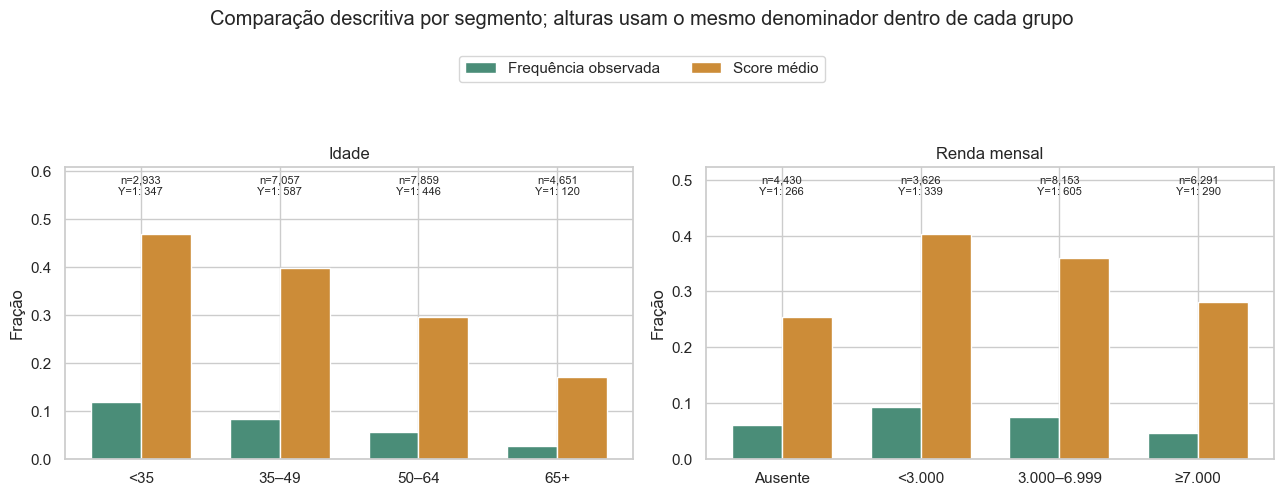

In [5]:
idade = pd.cut(X_hold['age'], [-np.inf, 35, 50, 65, np.inf],
               labels=['<35', '35–49', '50–64', '65+'], right=False)
renda = pd.cut(X_hold['MonthlyIncome'], [-np.inf, 3000, 7000, np.inf],
               labels=['<3.000', '3.000–6.999', '≥7.000'], right=False)
renda = renda.astype('object').where(X_hold['MonthlyIncome'].notna(), 'Ausente')

linhas_seg = []
for variavel, grupos, ordem in [
    ('idade', idade, ['<35', '35–49', '50–64', '65+']),
    ('renda_mensal', renda, ['Ausente', '<3.000', '3.000–6.999', '≥7.000']),
]:
    for nome in ordem:
        mask = np.asarray(grupos == nome)
        assert mask.sum() > 0
        linhas_seg.append({'variavel_segmento': variavel, 'segmento': nome,
                           **metricas(y[mask], p0[mask])})
segmentos = pd.DataFrame(linhas_seg)
segmentos.to_csv(OUT / '16_segmentos.csv', index=False, encoding='utf-8-sig')
display(segmentos.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for a, var, title in zip(axes, ['idade', 'renda_mensal'], ['Idade', 'Renda mensal']):
    t = segmentos.query('variavel_segmento == @var')
    x = np.arange(len(t))
    a.bar(x-.18, t['prevalencia'], width=.36, color='#4a8d78', label='Frequência observada')
    a.bar(x+.18, t['score_medio'], width=.36, color='#cc8c38', label='Score médio')
    a.set_xticks(x, t['segmento'])
    a.set(ylabel='Fração', title=title, ylim=(0, max(t['score_medio'].max(),t['prevalencia'].max())*1.30))
    for xi, n, pos in zip(x, t['n'], t['positivos']):
        a.text(xi, a.get_ylim()[1]*.97, f'n={n:,}\nY=1: {pos:,}', ha='center', va='top', fontsize=8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .95), ncol=2)
fig.suptitle('Comparação descritiva por segmento; alturas usam o mesmo denominador dentro de cada grupo', y=1.03)
fig.tight_layout(rect=(0, 0, 1, .86))
fig.savefig(FIGURES_DIR / '16_segmentos.png', dpi=170, bbox_inches='tight')
plt.show()

## 4. Erro de medição perto da fronteira: desenho

Para larguras $h\in\{0{,}02,0{,}05,0{,}10\}$, selecionamos $B_h=\{i:|s_i-0{,}50|\le h\}$ usando o score **antes** do estresse. As bandas são aninhadas e não correspondem a três amostras independentes. Para cada direção e intensidade $r\in\{-0{,}50,-0{,}45,\ldots,-0{,}05,0,+0{,}05,\ldots,+0{,}50\}$, alteramos somente o valor que o modelo recebe. São 21 níveis por banda, de 5% em 5%, incluindo o zero:

\[x'_{i,R}=\begin{cases}x_{i,R}(1+r), & i\in B_h,\\ x_{i,R}, & i\notin B_h,\end{cases}\]

em que $R$ é `RevolvingUtilizationOfUnsecuredLines`, $x_{i,R}$ é o valor original e $x'_{i,R}$ é o valor medido com erro. As outras nove entradas e o rótulo $y_i$ são idênticos. Zeros continuam zero após multiplicação; por isso mostramos a fração **efetivamente alterada**, e não apenas a intensidade pedida. O score novo é $s'_i=f(X'_i)$. Reportamos resultados tanto **no holdout completo** quanto **dentro da banda**, sempre indicando o denominador.

O **flip** é $1[1(s'_i\ge0{,}50)\ne1(s_i\ge0{,}50)]$. `score médio Δ pp` é $100(\bar s'-\bar s)$; `movimento absoluto pp` é $100n^{-1}\sum_i|s'_i-s_i|$, evitando cancelamento entre subidas e quedas. Métricas rotuladas são recalculadas com $s'$ e o mesmo $Y$ porque o cenário é um erro de entrada, não uma mudança real do risco. Para cada métrica principal calculamos também $\Delta M=M_{cenário}-M_{referência}$ separadamente no total e na banda. Deltas positivos de Brier indicam pior erro quadrático; deltas negativos de AUC, PR-AUC e KS indicam perda de separação. Nenhum delta interrompe a grade.

### PSI do valor entregue ao modelo

Fixamos as faixas com o **treino**: zero, ausente, negativos inválidos, valores positivos abaixo/acima do suporte e décimos dos positivos observados. Para cada faixa $b$, $q_b$ é a proporção original e $p_b$ a proporção após o erro; calculamos $PSI=\sum_b(p_b-q_b)\ln(p_b/q_b)$, adicionando $\varepsilon=10^{-9}$ a cada proporção e renormalizando para evitar log de zero. `PSI global` usa 22.500 linhas; `PSI banda` usa apenas $B_h$, com **os mesmos cortes do treino**. PSI depende dessas faixas, não tem limiar universal de perda e pode ser pequeno globalmente quando um subgrupo pequeno é muito afetado.

In [6]:
R = 'RevolvingUtilizationOfUnsecuredLines'
ref_pos = X_train[R].dropna().to_numpy(dtype=float)
ref_pos = ref_pos[ref_pos > 0]
assert len(ref_pos) > 0
min_pos, max_pos = float(ref_pos.min()), float(ref_pos.max())
cortes = np.unique(np.quantile(ref_pos, np.arange(.1, 1., .1)))
n_bins = 6 + len(cortes)

def codigos_psi(valores):
    v = np.asarray(valores, dtype=float)
    codes = np.zeros(len(v), dtype=np.int16)  # 0: ausente
    codes[v == 0] = 1                         # 1: zero
    codes[v < 0] = 2                          # 2: negativo inválido
    codes[(v > 0) & (v < min_pos)] = 3         # 3: positivo abaixo do treino
    interno = (v >= min_pos) & (v <= max_pos)
    codes[interno] = 4 + np.searchsorted(cortes, v[interno], side='right')
    codes[v > max_pos] = 5 + len(cortes)       # último: acima do treino
    assert ((codes >= 0) & (codes < n_bins)).all()
    return codes

def psi_mesmos_cortes(referencia, cenario):
    a, b = codigos_psi(referencia), codigos_psi(cenario)
    assert len(a) == len(b) and len(a) > 0
    q = np.bincount(a, minlength=n_bins)/len(a)
    p = np.bincount(b, minlength=n_bins)/len(b)
    eps = 1e-9
    q, p = q + eps, p + eps
    q, p = q/q.sum(), p/p.sum()
    return float(np.sum((p-q)*np.log(p/q)))

assert abs(psi_mesmos_cortes(X_hold[R], X_hold[R])) < 1e-12
print('Faixas fixas do PSI:', n_bins, '| mínimo positivo treino:', min_pos,
      '| máximo treino:', max_pos)

Faixas fixas do PSI: 15 | mínimo positivo treino: 1.43e-05 | máximo treino: 50708.0


In [7]:
X_ref = X_hold[R].to_numpy(dtype=float)
intensidades = np.arange(-50, 51, 5) / 100
larguras = [.02, .05, .10]
rows = []
for h in larguras:
    banda = np.abs(p0-CORTE) <= h
    assert banda.any() and np.unique(y[banda]).size == 2
    met_base_banda = metricas(y[banda], p0[banda])
    for r in intensidades:
        X_err = X_hold.copy()
        if r:
            X_err.loc[banda, R] = X_err.loc[banda, R] * (1+r)
        x_err = X_err[R].to_numpy(dtype=float)
        assert X_err.drop(columns=R).equals(X_hold.drop(columns=R))
        assert np.array_equal(np.isnan(x_err), np.isnan(X_ref))
        assert np.nanmin(x_err) >= 0
        pp = p0.copy() if r == 0 else prever(X_err)
        met_total = metricas(y, pp)
        met_banda = metricas(y[banda], pp[banda])
        mudou_input = ~np.isclose(x_err, X_ref, rtol=0, atol=0, equal_nan=True)
        flip = (pp >= CORTE) != (p0 >= CORTE)
        row = {
            'largura_banda': h, 'limite_score_inferior': CORTE-h,
            'limite_score_superior': CORTE+h,
            'intensidade_solicitada_pct': r*100,
            'n_banda': int(banda.sum()), 'positivos_banda': int(y[banda].sum()),
            'n_input_alterado_total': int(mudou_input.sum()),
            'fracao_input_alterado_total': float(mudou_input.mean()),
            'fracao_input_alterado_banda': float(mudou_input[banda].mean()),
            'psi_total': psi_mesmos_cortes(X_ref, x_err),
            'psi_banda': psi_mesmos_cortes(X_ref[banda], x_err[banda]),
            'flip_total_pct': float(100*flip.mean()),
            'flip_banda_pct': float(100*flip[banda].mean()),
            'delta_score_medio_total_pp': float(100*(pp.mean()-p0.mean())),
            'delta_score_medio_banda_pp': float(100*(pp[banda].mean()-p0[banda].mean())),
            'movimento_abs_score_total_pp': float(100*np.mean(np.abs(pp-p0))),
            'movimento_abs_score_banda_pp': float(100*np.mean(np.abs(pp[banda]-p0[banda]))),
            **{f'total_{k}':v for k,v in met_total.items()},
            **{f'banda_{k}':v for k,v in met_banda.items()},
        }
        for chave in ['auc_roc', 'pr_auc_trap', 'ks_modelo', 'brier', 'ap',
                      'recall_050', 'precision_050', 'fpr_050']:
            row[f'delta_total_{chave}'] = met_total[chave] - base[chave]
            row[f'delta_banda_{chave}'] = met_banda[chave] - met_base_banda[chave]
        rows.append(row)

stress = pd.DataFrame(rows)
assert len(stress) == len(larguras) * len(intensidades) == 63
assert stress.query('intensidade_solicitada_pct == 0')['psi_total'].abs().max() < 1e-12
assert stress.query('intensidade_solicitada_pct == 0')['flip_total_pct'].eq(0).all()
assert stress['n_banda'].min() > 100 and stress['positivos_banda'].min() > 20
assert np.isfinite(stress[['psi_total','psi_banda','total_auc_roc','total_pr_auc_trap',
                           'total_ks_modelo','total_brier','banda_auc_roc',
                           'banda_pr_auc_trap','banda_ks_modelo','banda_brier']]).all().all()
stress.to_csv(OUT / '16_stress_fronteira.csv', index=False, encoding='utf-8-sig')
display(stress[['largura_banda','intensidade_solicitada_pct','n_banda','positivos_banda',
                'fracao_input_alterado_banda','psi_total','psi_banda',
                'flip_total_pct','flip_banda_pct','total_auc_roc','total_pr_auc_trap',
                'total_ks_modelo','total_brier','total_ap','total_recall_050','total_precision_050',
                'banda_auc_roc','banda_pr_auc_trap','banda_ks_modelo','banda_brier',
                'banda_recall_050','banda_precision_050']].round(5))

,largura_banda,intensidade_solicitada_pct,n_banda,positivos_banda,fracao_input_alterado_banda,psi_total,psi_banda,flip_total_pct,flip_banda_pct,total_auc_roc,total_pr_auc_trap,total_ks_modelo,total_brier,total_ap,total_recall_050,total_precision_050,banda_auc_roc,banda_pr_auc_trap,banda_ks_modelo,banda_brier,banda_recall_050,banda_precision_050
0,0.02,-50.0,655,42,0.98168,0.00134,2.18655,1.40889,48.39695,0.86593,0.39549,0.58552,0.14154,0.39589,0.77800,0.22348,0.48489,0.06119,0.06102,0.16404,0.04762,0.08000
1,0.02,-45.0,655,42,0.98168,0.00113,2.04240,1.40889,48.39695,0.86612,0.39558,0.58548,0.14179,0.39597,0.77800,0.22339,0.48439,0.06120,0.04603,0.17264,0.04762,0.07407
2,0.02,-40.0,655,42,0.98168,0.00095,5.17053,1.39556,47.93893,0.86628,0.39565,0.58538,0.14201,0.39604,0.77800,0.22318,0.49246,0.06158,0.07970,0.18021,0.04762,0.06250
3,0.02,-35.0,655,42,0.98168,0.00095,1.81279,1.37333,47.17557,0.86653,0.39578,0.58600,0.14227,0.39618,0.77867,0.22307,0.51690,0.06640,0.09761,0.18892,0.07143,0.07692
4,0.02,-30.0,655,42,0.98168,0.00098,1.63273,1.34222,46.10687,0.86660,0.39584,0.58724,0.14247,0.39623,0.78000,0.22324,0.52707,0.07393,0.10821,0.19602,0.11905,0.11364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,0.10,30.0,3282,236,0.96801,0.00929,0.21598,4.08000,27.97075,0.86528,0.39406,0.57581,0.15354,0.39445,0.81867,0.19059,0.54830,0.08247,0.10200,0.31511,0.80085,0.07497
59,0.10,35.0,3282,236,0.96801,0.01127,0.25911,4.47111,30.65204,0.86520,0.39400,0.57433,0.15450,0.39440,0.82267,0.18889,0.54805,0.08375,0.08831,0.32164,0.82627,0.07468
60,0.10,40.0,3282,236,0.96801,0.01348,0.30822,4.80000,32.90676,0.86508,0.39393,0.57495,0.15531,0.39432,0.82467,0.18740,0.54654,0.08664,0.09007,0.32720,0.83898,0.07391
61,0.10,45.0,3282,236,0.96801,0.01575,0.35598,4.88889,33.51615,0.86514,0.39391,0.57795,0.15554,0.39431,0.82533,0.18698,0.54997,0.08568,0.10190,0.32877,0.84322,0.07373


## 5. Ler intensidade, drift e efeito em conjunto

Cada curva abaixo usa o percentual **aplicado apenas na banda** no eixo horizontal. Os pontos $r=0$ são as referências. Os painéis de PSI e flips distinguem o efeito no *holdout completo* do efeito **condicional à banda**. Se o PSI global for baixo e os flips na banda forem altos, isso mostra concentração local do efeito, não segurança universal do modelo.

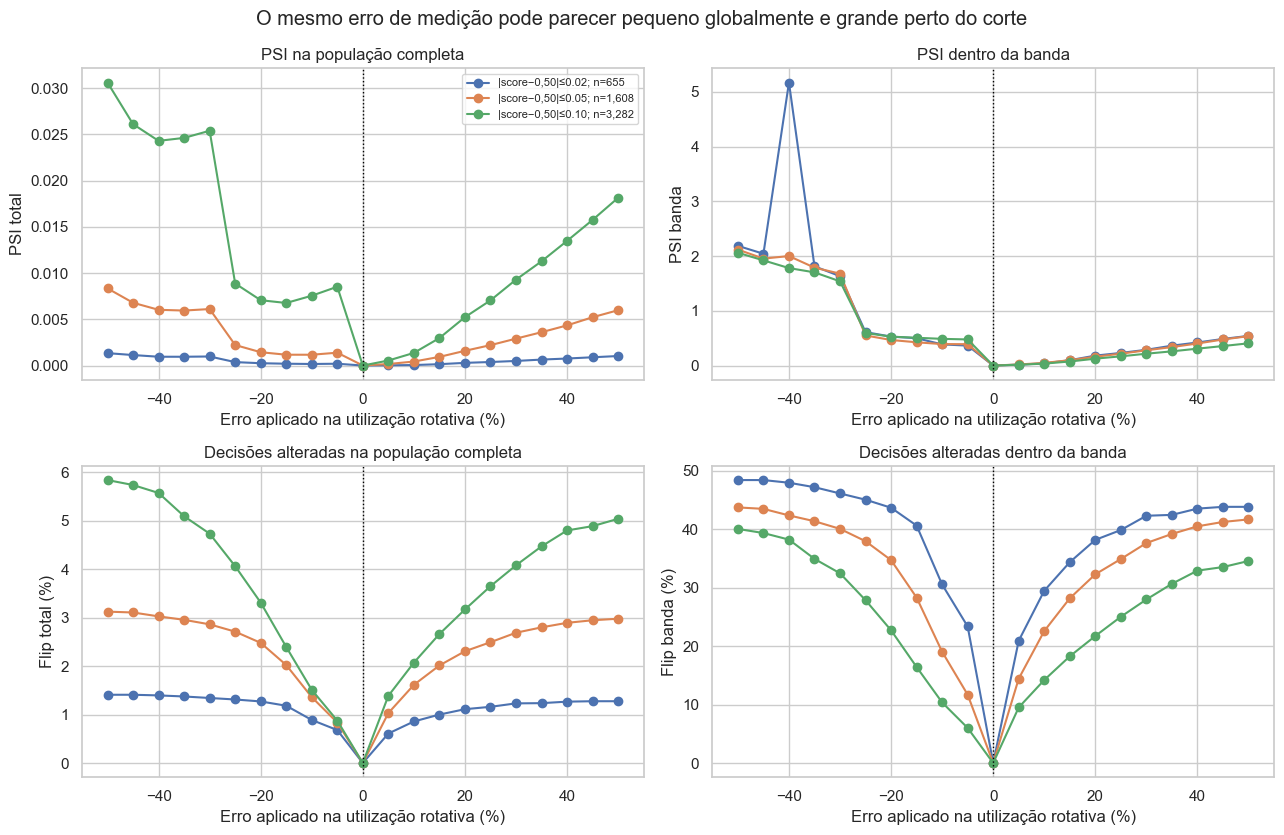

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for h, t in stress.groupby('largura_banda', sort=True):
    t = t.sort_values('intensidade_solicitada_pct')
    label = f'|score−0,50|≤{h:.2f}; n={int(t.n_banda.iloc[0]):,}'
    for ax, col in [(axes[0,0],'psi_total'),(axes[0,1],'psi_banda'),
                    (axes[1,0],'flip_total_pct'),(axes[1,1],'flip_banda_pct')]:
        ax.plot(t['intensidade_solicitada_pct'], t[col], 'o-', label=label)
for ax, title, ylab in [
    (axes[0,0], 'PSI na população completa', 'PSI total'),
    (axes[0,1], 'PSI dentro da banda', 'PSI banda'),
    (axes[1,0], 'Decisões alteradas na população completa', 'Flip total (%)'),
    (axes[1,1], 'Decisões alteradas dentro da banda', 'Flip banda (%)'),
]:
    ax.axvline(0, color='black', ls=':', lw=1)
    ax.set(xlabel='Erro aplicado na utilização rotativa (%)', ylabel=ylab, title=title)
axes[0,0].legend(fontsize=8)
fig.suptitle('O mesmo erro de medição pode parecer pequeno globalmente e grande perto do corte')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '16_stress_fronteira_psi_flips.png', dpi=170, bbox_inches='tight')
plt.show()

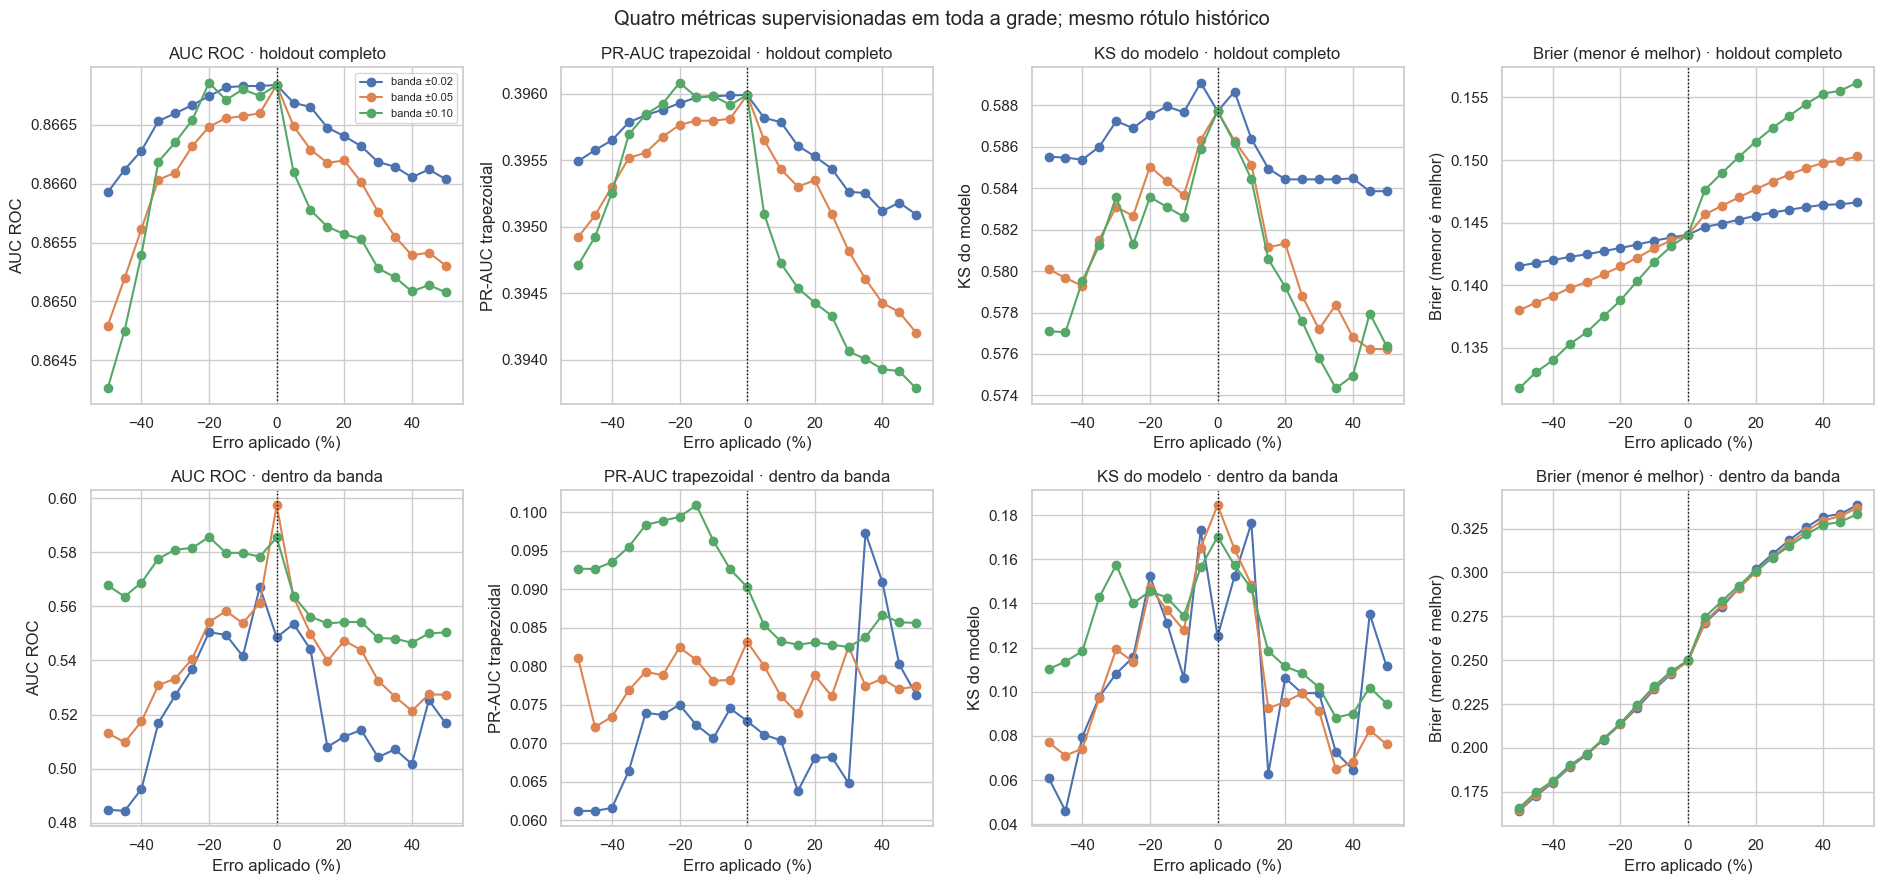

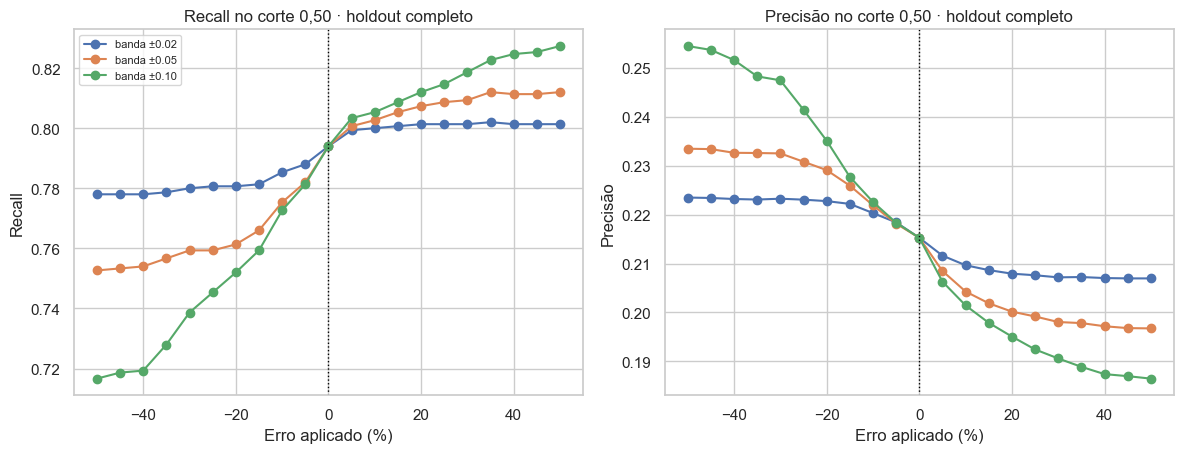

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
for linha, prefixo, denominador in [(0, 'total', 'holdout completo'),
                                     (1, 'banda', 'dentro da banda')]:
    for coluna, (chave, nome) in enumerate([
        ('auc_roc', 'AUC ROC'), ('pr_auc_trap', 'PR-AUC trapezoidal'),
        ('ks_modelo', 'KS do modelo'), ('brier', 'Brier (menor é melhor)')]):
        ax = axes[linha, coluna]
        for h, t in stress.groupby('largura_banda', sort=True):
            t = t.sort_values('intensidade_solicitada_pct')
            ax.plot(t['intensidade_solicitada_pct'], t[f'{prefixo}_{chave}'], 'o-',
                    label=f'banda ±{h:.2f}')
        ax.axvline(0, color='black', ls=':', lw=1)
        ax.set(xlabel='Erro aplicado (%)', ylabel=nome,
               title=f'{nome} · {denominador}')
axes[0,0].legend(fontsize=8)
fig.suptitle('Quatro métricas supervisionadas em toda a grade; mesmo rótulo histórico')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '16_stress_fronteira_metricas.png', dpi=170, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, (chave, titulo) in zip(axes, [('recall_050', 'Recall'),
                                     ('precision_050', 'Precisão')]):
    for h, t in stress.groupby('largura_banda', sort=True):
        t = t.sort_values('intensidade_solicitada_pct')
        ax.plot(t['intensidade_solicitada_pct'], t[f'total_{chave}'], 'o-',
                label=f'banda ±{h:.2f}')
    ax.set(xlabel='Erro aplicado (%)', ylabel=titulo,
           title=f'{titulo} no corte 0,50 · holdout completo')
    ax.axvline(0, color='black', ls=':', lw=1)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '16_stress_fronteira_referenciais.png', dpi=170, bbox_inches='tight')
plt.show()

## 6. Síntese automática e limites da inferência

A tabela seguinte destaca, para cada banda, o maior PSI e flip, além dos maiores **desvios absolutos** de AUC ROC, PR-AUC trapezoidal, KS do modelo e Brier entre as 20 intensidades não nulas. Mantemos o delta assinado para distinguir melhora de piora. Ela **não seleciona um limite de produção**: todos os cenários foram executados, sem guardrail de negócio ou parada.

In [10]:
linhas_resumo = []
for h, t in stress.query('intensidade_solicitada_pct != 0').groupby('largura_banda'):
    comum = {'largura_banda': h, 'n_banda': int(t.n_banda.iloc[0]),
             'positivos_banda': int(t.positivos_banda.iloc[0]),
             'psi_total_max': t.psi_total.max(), 'psi_banda_max': t.psi_banda.max(),
             'flip_total_max_pct': t.flip_total_pct.max(),
             'flip_banda_max_pct': t.flip_banda_pct.max()}
    for populacao in ['total', 'banda']:
        for metrica in ['auc_roc', 'pr_auc_trap', 'ks_modelo', 'brier']:
            delta = f'delta_{populacao}_{metrica}'
            i = t[delta].abs().idxmax()
            linhas_resumo.append({**comum, 'populacao': populacao, 'metrica': metrica,
                                  'intensidade_do_maior_desvio_pct': stress.loc[i, 'intensidade_solicitada_pct'],
                                  'maior_delta_assinado': stress.loc[i, delta]})
resumo = pd.DataFrame(linhas_resumo)
resumo.to_csv(OUT / '16_stress_fronteira_resumo.csv', index=False, encoding='utf-8-sig')
display(resumo.round(6))

,largura_banda,n_banda,positivos_banda,psi_total_max,psi_banda_max,flip_total_max_pct,flip_banda_max_pct,populacao,metrica,intensidade_do_maior_desvio_pct,maior_delta_assinado
0,0.02,655,42,0.001338,5.170527,1.408889,48.396947,total,auc_roc,-50.0,-0.000914
1,0.02,655,42,0.001338,5.170527,1.408889,48.396947,total,pr_auc_trap,50.0,-0.000900
2,0.02,655,42,0.001338,5.170527,1.408889,48.396947,total,ks_modelo,45.0,-0.003857
3,0.02,655,42,0.001338,5.170527,1.408889,48.396947,total,brier,50.0,0.002576
4,0.02,655,42,0.001338,5.170527,1.408889,48.396947,banda,auc_roc,-45.0,-0.064165
5,0.02,655,42,0.001338,5.170527,1.408889,48.396947,banda,pr_auc_trap,35.0,0.024430
6,0.02,655,42,0.001338,5.170527,1.408889,48.396947,banda,ks_modelo,-45.0,-0.079080
7,0.02,655,42,0.001338,5.170527,1.408889,48.396947,banda,brier,50.0,0.088505
8,0.05,1608,107,0.008340,2.118795,3.124444,43.718905,total,auc_roc,-50.0,-0.002049
9,0.05,1608,107,0.008340,2.118795,3.124444,43.718905,total,pr_auc_trap,50.0,-0.001789


**Como replicar em outro contexto.**

1. Congele o modelo, o corte, o esquema de variáveis e um *holdout* rotulado que não entrou no ajuste. Confirme o hash do artefato.
2. Calcule a referência com AUC ROC, PR-AUC trapezoidal, KS do modelo e Brier; apresente prevalência, `n`, AP adicional e recall/precisão em 0,50. Compare Brier com um preditor constante definido pelo treino.
3. Trace calibração e segmentos com contagem de casos e positivos. Fixe cortes de segmentos e bandas de score usando apenas treino ou score original, antes de ler os resultados dos cenários.
4. Especifique um **erro de medição** plausível, com variável, direção, intensidade, limites físicos e denominador. Mantenha o rótulo histórico somente se o valor verdadeiro do cliente não mudou.
5. Para cada banda, execute todos os níveis de −50% a +50% em passos de 5%, reiniciando da mesma entrada. Meça a fração realmente alterada: zeros, ausentes e truncamentos podem fazer a intensidade nominal divergir do efeito real.
6. Com faixas de PSI fixadas no treino, reporte drift, movimento de score, flips e as quatro métricas no holdout completo **e** dentro da banda; explicite os dois denominadores. Use recall e precisão como contexto, sem critério de parada.
7. Repita em safras temporais rotuladas e avalie incerteza e plausibilidade antes de transformar o resultado em regra de monitoramento. Uma mudança **real** do cliente exigiria outro desenho, pois seu desfecho contrafactual não é conhecido.

**Limites.** As bandas são subpopulações escolhidas pelo score do próprio modelo; suas métricas não representam a produção como um todo. A mudança percentual da utilização pode ser pouco plausível para alguns extremos e deixa os zeros iguais. A amostra não tem data nem informação sobre política de concessão. O PSI depende dos bins. Mesmo quando este teste de erro de medição permite manter $Y$, ele não estima o desfecho contrafactual de uma mudança **real** da utilização. O peso de classe alto pode melhorar a ordenação e piorar a calibração no corte fixo; este notebook não recalibra o modelo e não chama score de PD validada.

### Referências metodológicas

- [XGBoost — parâmetros do modelo](https://xgboost.readthedocs.io/en/stable/parameter.html): `scale_pos_weight` controla o equilíbrio dos pesos de classes no treinamento.
- [scikit-learn — calibração de probabilidades](https://scikit-learn.org/stable/modules/calibration.html): diagramas de confiabilidade e limites da leitura do Brier como medida isolada de calibração.
- [scikit-learn — Brier score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html): definição do erro quadrático de scores binários.